In [2]:
# Worker Ray mewarisi environment ini, jadi CUDA tidak dipakai sama sekali.
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"   # stacktrace CUDA akurat bila masih muncul
 
import argparse
import sys
import contextlib
import logging
import time
import traceback
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
from flwr.simulation import run_simulation
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.metrics import auc as sk_auc
 
import config
import fl_basic5 as fl          # <- ganti jika nama file strategy/client-mu berbeda
from dataset import DROP_COLS, TARGET
from model import build_model
 
# [FIX] paksa device proses utama ke CPU (selaras dengan num_gpus=0.0)
config.DEVICE = torch.device("cpu")
if hasattr(fl, "DEVICE"):
    fl.DEVICE = torch.device("cpu")
 
# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
ALGOS = ['fedavg', 'fedprox', 'fedavgm', 'fedadam', 'fedpairwise']
BASELINE = 'fedavg'
ORIG_OUT_DIR = Path(config.OUT_DIR)
ORIG_SEED = int(config.SEED)
 
SEEDS = [42, 0, 123, 1337, 3407]
 
SELEKSI_STATES = {
    'full':  None,
    'top10': [5, 10, 13, 16, 19, 23, 29, 39, 41, 54],
    'top20': [1, 5, 10, 12, 13, 16, 19, 22, 23, 29, 30, 33, 34, 37, 39, 41, 48, 50, 54, 55]
}
SELEKSI = 'top20'
 
METRIC_COLS = ['acc', 'prec', 'rec', 'f1', 'auc', 'ap',
               'f1_macro', 'f1_std_klien', 'total_MB', 'waktu_s']
PAIRED_METRICS = ('f1', 'auc', 'ap')
 
# ---- logging ----
VERBOSE = False
LOG_DIR = ORIG_OUT_DIR.parent
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_FLWR = LOG_DIR / 'flwrTop20.log'
LOG_PRINTS = LOG_DIR / 'printsTop20.log'
 
# %%
 
def setup_flwr_logging():
    """Console Flower hanya WARNING+; detail penuh ke file. Aman dipanggil berulang."""
    lg = logging.getLogger("flwr")
    for h in lg.handlers:
        if not isinstance(h, logging.FileHandler):
            h.setLevel(logging.WARNING)
    if not any(isinstance(h, logging.FileHandler) for h in lg.handlers):
        fh = logging.FileHandler(LOG_FLWR, encoding="utf-8")
        fh.setLevel(logging.INFO)
        fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
        lg.addHandler(fh)
    lg.setLevel(logging.INFO)
 
 
@contextlib.contextmanager
def quiet(logfile=None):
    """Alihkan print() ke file. Dinonaktifkan bila VERBOSE."""
    if VERBOSE:
        yield
        return
    with open(logfile or LOG_PRINTS, "a", encoding="utf-8") as f, \
            contextlib.redirect_stdout(f):
        yield
 
 
setup_flwr_logging()

c:\Users\s2\Documents\FIXRKI\.fed\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-23 15:07:28,776	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


Modul FL: fl_basic5 (fl_basic5.py)
Agregasi pairwise dari modul: aggregation4
Dataset : C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients (45 item)
Seleksi               : top20
Jumlah client (state) : 20
Daftar state          : [1, 5, 10, 12, 13, 16, 19, 22, 23, 29, 30, 33, 34, 37, 39, 41, 48, 50, 54, 55]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dilatih/ronde  : 20 dari 20
Local epochs          : 5
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnkany6
 32. flushot7
 33. pneuvac4
 34. marital_1
 35. marital_2
 

[selesai] fedavg s42: F1 test 0.4928 | AUC 0.7376 | AP 0.4498 | 15.90 MB | 91.2 s

########## fedprox | seed 42 ##########


[selesai] fedprox s42: F1 test 0.4913 | AUC 0.7388 | AP 0.4528 | 15.90 MB | 167.1 s

########## fedavgm | seed 42 ##########


[selesai] fedavgm s42: F1 test 0.3996 | AUC 0.6505 | AP 0.3519 | 15.90 MB | 86.5 s

########## fedadam | seed 42 ##########


[selesai] fedadam s42: F1 test 0.4760 | AUC 0.7156 | AP 0.4129 | 15.90 MB | 86.3 s

########## fedpairwise | seed 42 ##########


...

[selesai] fedavg s3407: F1 test 0.4960 | AUC 0.7386 | AP 0.4486 | 15.90 MB | 87.7 s

########## fedprox | seed 3407 ##########


[selesai] fedprox s3407: F1 test 0.4980 | AUC 0.7412 | AP 0.4522 | 15.90 MB | 177.1 s

########## fedavgm | seed 3407 ##########


[selesai] fedavgm s3407: F1 test 0.3101 | AUC 0.5729 | AP 0.2906 | 15.90 MB | 87.6 s

########## fedadam | seed 3407 ##########


[selesai] fedadam s3407: F1 test 0.4700 | AUC 0.7146 | AP 0.4079 | 15.90 MB | 87.8 s

########## fedpairwise | seed 3407 ##########


[selesai] fedpairwise s3407: F1 test 0.4971 | AUC 0.7439 | AP 0.4601 | 15.90 MB | 88.9 s

PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)
             n_seed              acc             prec              rec               f1              auc               ap     f1_std_klien      total_MB        waktu_s
algoritma                                                                                                                                                              
fedpairwise       5  0.7065 ± 0.0030  0.4118 ± 0.0029  0.6240 ± 0.0086  0.4961 ± 0.0024  0.7437 ± 0.0007  0.4636 ± 0.0040  0.0317 ± 0.0050  15.90 ± 0.00   87.24 ± 1.03
fedprox           5  0.7028 ± 0.0029  0.4083 ± 0.0026  0.6299 ± 0.0094  0.4954 ± 0.0025  0.7411 ± 0.0016  0.4572 ± 0.0048  0.0329 ± 0.0033  15.90 ± 0.00  169.96 ± 4.54
fedavg            5  0.7040 ± 0.0033  0.4088 ± 0.0027  0.6223 ± 0.0105  0.4934 ± 0.0020  0.7394 ± 0.0018  0.4539 ± 0.0049  0.0322 ± 0.0032  15.90 ± 0.00   87.88 ± 1.95
fed

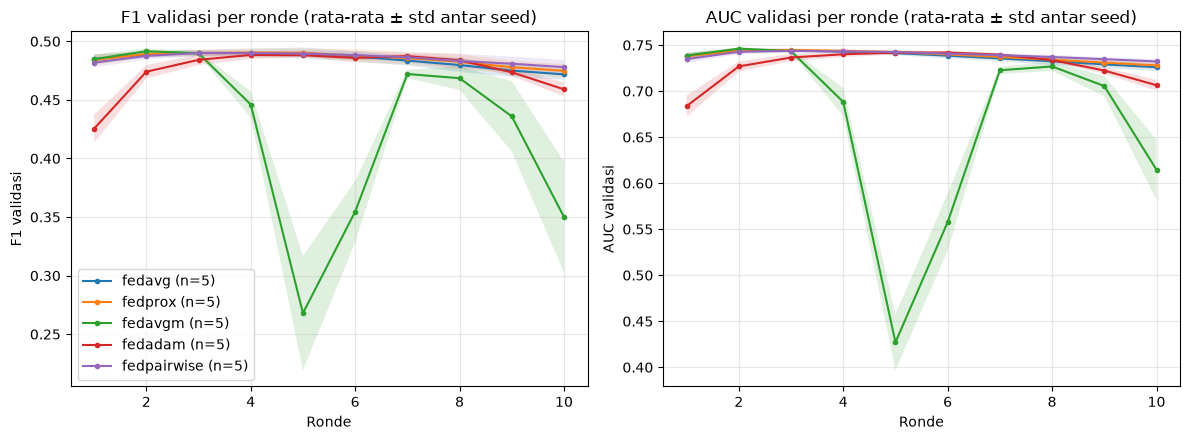

Grafik disimpan: C:\Users\s2\Documents\FIXRKI\FIXbanget\baselinefed\hasil_top20\kurva_roc_pr_test.png


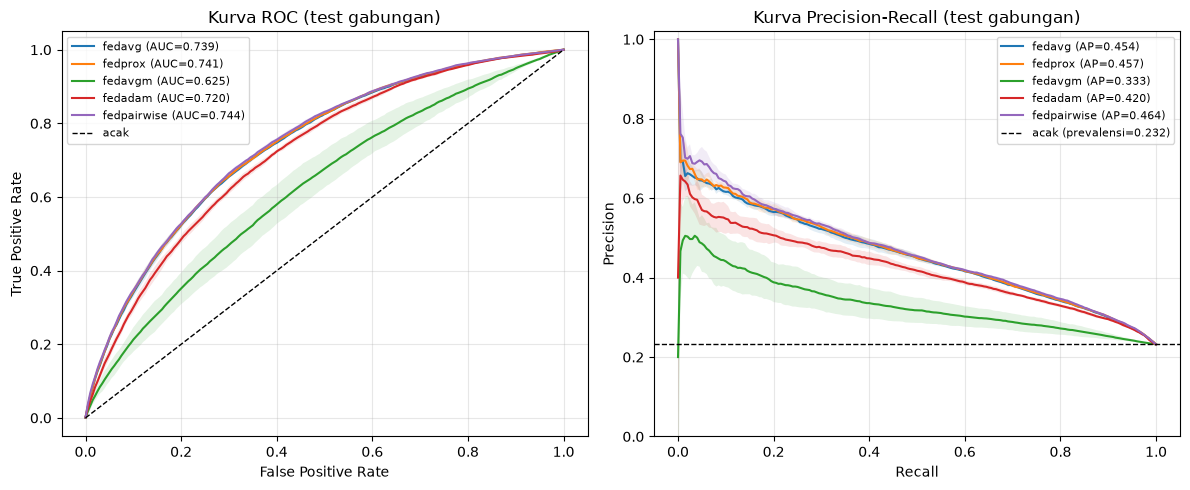

In [3]:
# %%
# ============================================================
# 1. DATASET, MODUL & RINGKASAN DATA
# ============================================================
def setup_dataset(seleksi):
    """Arahkan config ke folder dataset, kirim seleksi lewat env, buang cache lama."""
    if not CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {CLIENT_DIR}")
    config.CLIENT_DIR = CLIENT_DIR
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)

    states = SELEKSI_STATES[seleksi]
    if states is None:
        os.environ.pop('FL_STATES', None)
    else:
        os.environ['FL_STATES'] = ','.join(map(str, states))
    os.environ['FL_SELEKSI'] = seleksi

    try:
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    clear = getattr(fl.load_data, 'cache_clear', None)
    if clear:
        clear()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")


def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")


def available_algos(algos):
    known = getattr(fl, 'ALGOS', algos)
    ok = [a for a in algos if a in known]
    skip = [a for a in algos if a not in ok]
    if skip:
        print(f"[lewati] tidak ada di {fl.__name__}.ALGOS: {skip}")
    return ok


def data_summary(seleksi):
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"

    # pastikan seleksi benar-benar diterapkan oleh load_data
    expected = SELEKSI_STATES[seleksi]
    if expected is not None:
        got = sorted(int(s) for s in fl.state_list())
        if got != sorted(expected):
            sys.exit(f"Seleksi '{seleksi}' tidak diterapkan oleh load_data.\n"
                     f"  diharapkan: {sorted(expected)}\n  didapat   : {got}\n"
                     f"Pasang hook FL_STATES di load_data (bagian A).")

    print("=" * 50)
    print(f"Seleksi               : {seleksi}")
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    for i, nama in enumerate(feature_names, 1):
        print(f"{i:>3}. {nama}")

    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}

    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)

    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total

    print("\nRingkasan per client:")
    print(ringkas.to_string())

    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
    return n_clients


# %%
# ============================================================
# 2. JALANKAN SATU (ALGORITMA, SEED)
# ============================================================
def run_algo(algo, seed, n_clients, out_root):
    """Simulasi FL untuk satu algoritma & seed; output ke out_root/out_<algo>_s<seed>."""
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)
    config.OUT_DIR = out_root / f'out_{algo}_s{seed}'
    config.ensure_out_dir()
    for nama in ('final_params.npz', 'ronde_log.csv'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
    print(f"\n########## {algo} | seed {seed} ##########")
    setup_flwr_logging()
    with quiet():
        run_simulation(
            server_app=fl.make_server_app(algo),
            client_app=fl.make_client_app(),
            num_supernodes=n_clients,
            backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0}},
        )


def load_global_model():
    path = config.OUT_DIR / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {config.OUT_DIR / 'client_error.log'}")
    d = np.load(path)
    w = [d[f'arr_{i}'] for i in range(len(d.files))]
    m = build_model(fl.get_in_dim(), seed=config.SEED).to(config.DEVICE)
    fl.set_weights(m, w)
    return m


# %%
# ============================================================
# 2b. METRIK DIAGNOSTIK: AUC-ROC, PR CURVE / AP
# ============================================================
def _to_prob(out):
    out = np.asarray(out, dtype=np.float64)
    if out.ndim == 2 and out.shape[1] == 2:
        if out.min() < 0 or out.max() > 1 or not np.allclose(out.sum(1), 1, atol=1e-3):
            e = np.exp(out - out.max(1, keepdims=True))
            out = e / e.sum(1, keepdims=True)
        return out[:, 1]
    out = out.reshape(-1)
    if out.min() < 0.0 or out.max() > 1.0:
        out = 1.0 / (1.0 + np.exp(-out))
    return out


def predict_proba_clients(model, split='test'):
    clients, _, _ = fl.load_data()
    model.eval()
    ys, ps = {}, {}
    with torch.no_grad():
        for st, c in clients.items():
            xk, yk = f'X_{split}_t', f'y_{split}_t'
            if xk not in c:
                raise KeyError(f"Kunci '{xk}' tidak ada di data client. "
                               f"Kunci tersedia: {list(c.keys())}  -> sesuaikan xk.")
            out = model(c[xk].to(config.DEVICE)).detach().cpu().numpy()
            ps[st] = _to_prob(out)
            ys[st] = c[yk].detach().cpu().numpy().reshape(-1).astype(int)
    return ys, ps


def diagnostic_metrics(model, split='test'):
    ys, ps = predict_proba_clients(model, split)
    y_all = np.concatenate(list(ys.values()))
    p_all = np.concatenate(list(ps.values()))

    def _safe(fn, y, p):
        return float(fn(y, p)) if 0 < y.sum() < len(y) else float('nan')

    per_state = pd.DataFrame({
        st: {'auc': _safe(roc_auc_score, ys[st], ps[st]),
             'ap': _safe(average_precision_score, ys[st], ps[st]),
             'prevalensi': float(ys[st].mean())}
        for st in ys}).T
    per_state.index.name = 'state'

    fpr, tpr, _ = roc_curve(y_all, p_all)
    prec, rec, _ = precision_recall_curve(y_all, p_all)
    return {
        'auc': _safe(roc_auc_score, y_all, p_all),
        'ap': _safe(average_precision_score, y_all, p_all),
        'prevalensi': float(y_all.mean()),
        'per_state': per_state,
        'roc': (fpr, tpr),
        'pr': (rec, prec),
    }


def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)

            rep, ronde = fl.bandwidth_report()
            print(ronde.round(4).to_string(index=False))

            model = load_global_model()
            df_test = fl.evaluate_on_clients(model, split='test')
            print(df_test.round(4).to_string())
            print(fl.summarize(df_test).round(4).to_string())
            print("Pooled:", fl.evaluate_pooled(model, split='test'))

            diag = diagnostic_metrics(model, 'test')
            print(f"AUC-ROC gabungan : {diag['auc']:.4f}")
            print(f"AP gabungan      : {diag['ap']:.4f}  "
                  f"(garis dasar acak = prevalensi {diag['prevalensi']:.4f})")
            print("AUC / AP per state:")
            print(diag['per_state'].round(4).to_string())
    finally:
        config.SEED = ORIG_SEED


# %%
def collect_result(secs):
    model   = load_global_model()
    pooled  = fl.evaluate_pooled(model, split='test')
    df_test = fl.evaluate_on_clients(model, split='test')
    ronde   = pd.read_csv(config.OUT_DIR / 'ronde_log.csv')
    bw, _   = fl.bandwidth_report(verbose=False)
    diag    = diagnostic_metrics(model, 'test')

    f1 = ronde['f1'].astype(float).reset_index(drop=True)
    ronde = ronde.reset_index(drop=True)
    val_akhir = float(f1.iloc[-1]) if len(f1) else float('nan')
    if f1.notna().any():
        best = f1.idxmax()
        val_best, best_round = float(f1[best]), int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1

    rec, prec = diag['pr']
    pr_auc = float(sk_auc(rec, prec)) if len(rec) > 1 else float('nan')

    pooled_num = {k: float(v) for k, v in pooled.items()
                  if np.isscalar(v) and v is not None}

    row = {
        **pooled_num,
        'auc':            diag['auc'],
        'ap':             diag['ap'],
        'prauc':          pr_auc,
        'prevalensi':     diag['prevalensi'],
        'f1_macro_klien': float(df_test['f1'].mean()),
        'f1_std_klien':   float(df_test['f1'].std()),
        'val_f1_akhir':   val_akhir,
        'val_f1_terbaik': val_best,
        'ronde_terbaik':  best_round,
        'total_MB':       float(bw['total_MB']),
        'waktu_s':        round(secs, 1),
    }
    return row, df_test['f1'], ronde, diag


def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"


def summarize_seeds(per_seed):
    cols = [c for c in METRIC_COLS if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')

    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    num = num.sort_values('f1_mean', ascending=False)

    tampil = pd.DataFrame(index=num.index)
    tampil['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s') else 4
        tampil[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                          int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return num, tampil


def _pvalue(d):
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)


def paired_vs_baseline(per_seed, baseline, metrics=PAIRED_METRICS):
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None


def _get_plt():
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        return plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return None


def _finish(plt, fig, out_path):
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)


def plot_curves(kurva, out_path):
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, col, judul in zip(axes, ('f1', 'auc'), ('F1 validasi', 'AUC validasi')):
        for algo, rs in per_algo.items():
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values, alpha=0.15)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde (rata-rata ± std antar seed)')
        ax.grid(alpha=0.3)
    axes[0].legend()
    _finish(plt, fig, out_path)


def plot_roc_pr(diags, out_path):
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), d in diags.items():
        per_algo.setdefault(algo, []).append(d)

    grid = np.linspace(0, 1, 201)
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))

    for algo, ds in per_algo.items():
        tprs = np.array([np.interp(grid, *d['roc']) for d in ds])
        precs = np.array([np.interp(grid, d['pr'][0][::-1], d['pr'][1][::-1]) for d in ds])
        auc_m = np.nanmean([d['auc'] for d in ds])
        ap_m = np.nanmean([d['ap'] for d in ds])

        mu = tprs.mean(0)
        ax_roc.plot(grid, mu, label=f'{algo} (AUC={auc_m:.3f})')
        mu_p = precs.mean(0)
        ax_pr.plot(grid, mu_p, label=f'{algo} (AP={ap_m:.3f})')
        if len(ds) > 1:
            sd = tprs.std(0, ddof=1)
            ax_roc.fill_between(grid, mu - sd, mu + sd, alpha=0.12)
            sd_p = precs.std(0, ddof=1)
            ax_pr.fill_between(grid, mu_p - sd_p, mu_p + sd_p, alpha=0.12)

    prev = np.mean([d['prevalensi'] for ds in per_algo.values() for d in ds])
    ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='acak')
    ax_pr.axhline(prev, color='k', ls='--', lw=1, label=f'acak (prevalensi={prev:.3f})')

    ax_roc.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
               title='Kurva ROC (test gabungan)')
    ax_pr.set(xlabel='Recall', ylabel='Precision',
              title='Kurva Precision-Recall (test gabungan)', ylim=(0, 1.02))
    for ax in (ax_roc, ax_pr):
        ax.grid(alpha=0.3)
        ax.legend(loc='best', fontsize=8)
    _finish(plt, fig, out_path)


def run_compare(algos, seeds, n_clients, out_root):
    rows, f1_klien, kurva, diags = {}, {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} algoritma x {len(seeds)} seed = {total_run} run")
    print(f"Seed: {seeds}")
    print(f"Log detail: {LOG_FLWR} | {LOG_PRINTS}")

    try:
        for seed in seeds:
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, f1c, ronde, diag = collect_result(time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], f1_klien[key], kurva[key], diags[key] = row, f1c, ronde, diag
                print(f"[selesai] {algo} s{seed}: F1 test {row['f1']:.4f} | "
                      f"AUC {row['auc']:.4f} | AP {row['ap']:.4f} | "
                      f"{row['total_MB']:.2f} MB | {row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED

    if not rows:
        sys.exit("Tidak ada run yang berhasil.")

    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)

    num, tampil = summarize_seeds(per_seed)
    berpasangan = paired_vs_baseline(per_seed, BASELINE)

    per_klien = pd.DataFrame({
        algo: pd.concat([f1_klien[k] for k in f1_klien if k[0] == algo], axis=1).mean(axis=1)
        for algo in num.index
    })
    per_klien.loc['MAKRO'] = per_klien.mean()

    ap_klien = pd.DataFrame({
        algo: pd.concat([diags[k]['per_state']['ap'] for k in diags if k[0] == algo],
                        axis=1).mean(axis=1)
        for algo in num.index
    })
    ap_klien.loc['MAKRO'] = ap_klien.mean()

    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)")
    print("=" * 70)
    print(tampil.to_string())

    print("\nHasil per seed (F1 | AUC | AP test gabungan):")
    print(per_seed[['f1', 'auc', 'ap']].round(4).unstack('seed').to_string())

    if berpasangan is not None:
        print(f"\nSelisih terhadap {BASELINE} pada seed yang sama "
              f"(positif = lebih baik dari {BASELINE}):")
        print(berpasangan.round(4).to_string())
        if int(berpasangan['n_seed'].min()) < 5:
            print("Catatan: dengan <5 seed uji-t lemah; jangan terlalu bergantung "
                  "pada p-value. Lihat kolom *_menang dan konsistensi arah selisih.")
    elif len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/ gagal.")

    print("\nF1 test per state (rata-rata antar seed):")
    print(per_klien.round(4).to_string())
    print("\nAP test per state (rata-rata antar seed):")
    print(ap_klien.round(4).to_string())

    print(f"\nTerbaik F1 (rata-rata)    : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC (rata-rata)   : {num['auc_mean'].idxmax()}")
    print(f"Terbaik AP (rata-rata)    : {num['ap_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed  : {num['f1_std'].idxmin()} (std F1 terkecil)")
    print(f"Paling merata antar state : {num['f1_std_klien_mean'].idxmin()}")
    mb = num['total_MB_mean']
    if (mb.max() - mb.min()) > 0.01 * mb.max():
        print(f"Bandwidth terkecil        : {mb.idxmin()}")
    else:
        print("Bandwidth                 : sama untuk semua algoritma (ukuran parameter sama)")

    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan.csv')
    per_klien.to_csv(out_root / 'perbandingan_f1_per_client.csv')
    ap_klien.to_csv(out_root / 'perbandingan_ap_per_client.csv')
    if berpasangan is not None:
        berpasangan.to_csv(out_root / 'perbandingan_berpasangan.csv')
    print(f"\nCSV disimpan di: {out_root}")
    plot_curves(kurva, out_root / 'kurva_validasi.png')
    plot_roc_pr(diags, out_root / 'kurva_roc_pr_test.png')
    return per_seed, num


# %%
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description="Simulasi Federated Learning")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu algoritma saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar algoritma untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4 (opsional)")
    ap.add_argument('--seleksi', default=SELEKSI, choices=list(SELEKSI_STATES),
                    help="'full' = semua state, 'top20' = 20 state terpilih")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    args, _ = ap.parse_known_args(argv)

    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
    seleksi = args.seleksi

    show_modules()
    setup_dataset(seleksi)
    n_clients = data_summary(seleksi)
    if args.info:
        return

    out_root = ORIG_OUT_DIR.parent / f'hasil_{seleksi}'

    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)


if __name__ == '__main__':
    main()